In [96]:
import numpy as np
from copy import deepcopy
import gwinc
import matplotlib.pyplot as plt

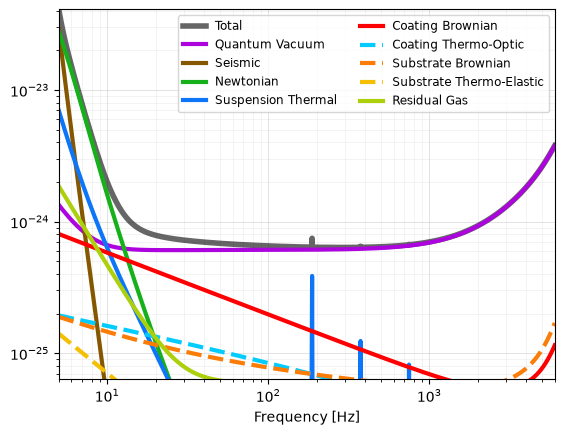

In [236]:
budget = gwinc.load_budget("../../../ifo/variant/OzCE-20.yaml")
ifo = deepcopy(budget.ifo)
fig = budget.run().plot()

In [256]:
class arm_cavity_stuff():
    def __init__(self, ifo):
        self.ifo = ifo
        self.params = {}
        self.rt_mat = None
        self.q_param = None
        self.gouy = None
        self.fsr = None
        self.msf = None
        self.homs = None



    def find_cav_params(self):
        self.params["length"] = deepcopy(self.ifo.Infrastructure.Length)
        self.params["Rc_ETM"] = deepcopy(self.ifo.Optics.Curvature.ETM)
        self.params["Rc_ITM"] = deepcopy(self.ifo.Optics.Curvature.ITM)

    def round_trip_mat(self):
        ref1_mat = np.array([ [1, 0], [-2/self.params["Rc_ITM"], 1]], dtype=np.complex128)
        ref2_mat = np.array([ [1, 0], [-2/self.params["Rc_ETM"], 1]], dtype=np.complex128)
        space_mat = np.array([ [1, self.params["length"]], [0, 1]], dtype=np.complex128)
        self.rt_mat = np.linalg.multi_dot([ref1_mat, space_mat, ref2_mat, space_mat])

    def solve_rt(self):
        m00 = self.rt_mat[0,0]
        m01 = self.rt_mat[0,1]
        m10 = self.rt_mat[1,0]
        m11 = self.rt_mat[1,1]
        a = m10
        b = m11 - m00
        c = -m01
        q_sol_1 = (-b + np.sqrt(b**2- 4*a*c))/(2*a)
        q_sol_2 = (-b - np.sqrt(b**2- 4*a*c))/(2*a)
        if np.imag(q_sol_1) > 0:
            self.q_param = q_sol_1
        elif np.imag(q_sol_2) > 0:
            self.q_param = q_sol_2
        else:
            self.q_param = 0
            print("Error: Cavity Unstable")
    
    def gouy_phase(self):
        A = self.rt_mat[0,0]
        B = self.rt_mat[0,1]
        C = self.rt_mat[1,0]
        D = self.rt_mat[1,1]
        self.gouy = np.real(2*np.arccos(np.sign(B)*np.sqrt((A+D+2)/4)))
        self.fsr = np.real((3e8/2/self.params["length"]))
        self.msf = np.real(self.gouy/(np.pi*2)*self.fsr)

    def homs_freq(self, n):
        mode_range = np.arange(n)
        self.homs = np.mod(self.msf*mode_range, self.fsr)
        
        

In [257]:
arm_cav_1 = arm_cavity_stuff(ifo)

In [356]:
arm_cav_1.find_cav_params()
arm_cav_1.params["Rc_ETM"] = 10957
arm_cav_1.params["Rc_ITM"] = 10957
arm_cav_1.round_trip_mat()
arm_cav_1.solve_rt()
arm_cav_1.gouy_phase()
arm_cav_1.homs_freq(20)

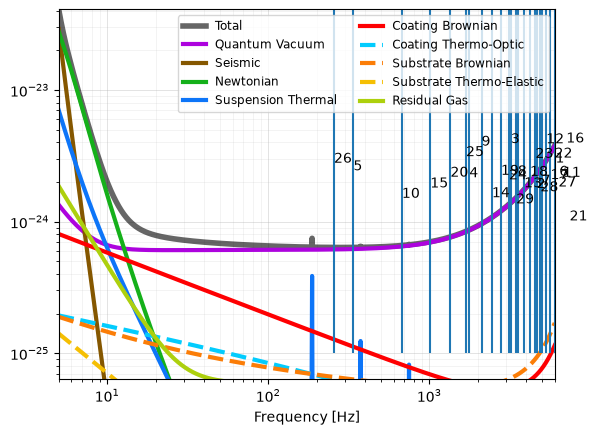

In [357]:
n=30

arm_cav_1.homs_freq(n)
fig2 = deepcopy(fig)
axes = fig2.gca()
axes.vlines(arm_cav_1.homs, 1e-25, 1e-22)
for i in np.arange(n):
    a = 3*np.random.random()+1
    axes.text(arm_cav_1.homs[i],1e-24*a, str(i))
fig2